# TEM-1: embedding congelati e regressione Ridge

Confronto supervisionato su **4.996 sostituzioni** di TEM-1. Gli embedding ESM-2 150M sono già estratti: questo notebook richiama il modulo comune `tem1.supervised`, valida gli input e presenta le predizioni salvate. Non avvia training o inferenza pLM.

Per generare gli output dalla radice del progetto: `python -m tem1.supervised --output results/supervised_repeat`. Consultare il [README](README.md) per installazione e comandi.

L’estensione mirata confronta **sito + delta (1.280)** con **sito + delta + media globale (1.920)**. Legge il nuovo run `results/supervised_esm2_150m_global` mantenendo tutti i risultati precedenti. Per replicarla usare `python -m tem1.supervised --representations emb_mut_pos_delta emb_mut_pos_delta_mean_pooled --output results/supervised_global_repeat`.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tem1.supervised import (InputPaths, DEFAULT_OUTPUT, load_inputs, load_results,
                            result_table, metric_values)
from tem1.data import sha256

# Funziona con kernel avviato dalla radice della repository o dalla cartella superiore.
ROOT = Path.cwd()
if not (ROOT / "stiffler_single_folds.csv").exists():
    ROOT = ROOT / "Bioscience-PLM"
paths = InputPaths(*(ROOT / p for p in
                    ["esm_variant_features.parquet", "stiffler_single_folds.csv", "esm_wt.npz",
                     "proteingym_substitutions.zip", "results/scale_gpu/150m"]))
data = load_inputs(paths)
predictions, result = load_results(ROOT / DEFAULT_OUTPUT)
for name, expected in result["input_sha256"].items():
    path = Path(name)
    assert sha256(path if path.is_absolute() else ROOT / path) == expected
assert predictions["mutant"].tolist() == data.rows["mutant"].tolist()
for column in ["position", "fold", "DMS_score", "zeroshot_wt", "zeroshot_masked"]:
    np.testing.assert_array_equal(predictions[column], data.rows[column])
# Il nuovo run conserva il precedente: si aggiunge solo la nuova colonna.
BASE_METHOD = "ridge_emb_mut_pos_delta"
GLOBAL_METHOD = "ridge_emb_mut_pos_delta_mean_pooled"
global_predictions, global_result = load_results(ROOT / "results/supervised_esm2_150m_global")
assert global_result["input_sha256"] == result["input_sha256"]
for key in result["configuration"]:
    if key not in ("representations", "args"):
        assert global_result["configuration"][key] == result["configuration"][key], key
assert global_result["environment"]["packages"] == result["environment"]["packages"]
assert global_predictions["mutant"].tolist() == predictions["mutant"].tolist()
for column in ["position", "fold", "DMS_score", "zeroshot_wt", "zeroshot_masked", BASE_METHOD]:
    np.testing.assert_array_equal(global_predictions[column], predictions[column])
methods = {**result["methods"], GLOBAL_METHOD: global_result["methods"][GLOBAL_METHOD]}
predictions[GLOBAL_METHOD] = global_predictions[GLOBAL_METHOD]
for method, report in methods.items():
    actual = metric_values(predictions["DMS_score"], predictions[method], report["kind"] == "ridge")
    for metric, value in actual.items():
        np.testing.assert_allclose(value, report["oof_metrics"][metric], atol=1e-12, rtol=0)
print(f"Validati {len(predictions):,} mutanti, {data.validation['n_positions']} posizioni: "
      "stesse varianti e stessi target per tutti i metodi.")

Validati 4,996 mutanti, 263 posizioni: stesse varianti e stessi target per tutti i metodi.


## Dati e rappresentazioni

`DMS_score` misura la prestazione sperimentale relativa al WT sotto ampicillina: più alto significa fitness maggiore nel saggio. Esempi delle varianti: nella tabella dei fold è visibile la ripartizione completa, senza esclusioni.

Ogni rappresentazione deriva dalla **sequenza mutata** e ha 640 componenti: `emb_mut_pos` è il vettore del residuo mutato; `mean_local_5/10/20` sono medie entro ±5/10/20 residui, limitate ai bordi; `mean_pooled` è la media di tutti i residui. `emb_mut_pos_delta` concatena il vettore mutato e la differenza dal WT allo stesso sito (**1.280 componenti**). La nuova `emb_mut_pos_delta_mean_pooled` aggiunge a quei 1.280 valori le 640 componenti di `mean_pooled` della stessa sequenza mutata, per un totale di **1.920**. Gli input sono memorizzati FP16 e convertiti in float64 per Ridge; il pLM resta congelato.

In [2]:
print("Esempi:", ", ".join(data.rows["mutant"].head(5)))
fold_table = data.rows.groupby("fold").agg(
    variants=("mutant", "size"), positions=("position", "nunique"),
    target_min=("DMS_score", "min"), target_max=("DMS_score", "max"))
assert data.rows.groupby("position")["fold"].nunique().eq(1).all()
display(fold_table.round(3))

Esempi: H24C, H24Y, H24W, H24V, H24T


,variants,positions,target_min,target_max
fold,,,,
0,1007,53,-3.743,0.300
1,1007,53,-3.538,0.356
2,1006,53,-3.494,0.107
3,988,52,-3.575,0.111
4,988,52,-3.577,0.136


## Protocollo comune

I **5 fold esterni per posizione** sono fissati nel CSV. Per ciascun fold si addestra sugli altri quattro; ogni variante riceve una sola predizione **fuori training (OOF)**. All'interno del solo training esterno, `GroupKFold(4)` sceglie alpha minimizzando la media degli **MSE** di validazione. `StandardScaler` è dentro la pipeline: viene appreso soltanto dai dati di training di ogni split. Il modello scelto viene riaddestrato su tutto il training esterno.

La griglia originale contiene 16 alpha da 0,01 a circa 316.228, con passi di mezzo ordine di grandezza. Nessuna posizione passa tra training e validazione/test nello stesso split. Le rappresentazioni condividono protocollo e split.

I due **zero-shot**, senza fitting sulle etichette DMS, sono riutilizzati sulle identiche varianti di test: **WT-marginals** usa il WT visibile, mentre **masked-marginals** nasconde il sito. Gli score esprimono preferenze probabilistiche: per loro confrontiamo Spearman, senza RMSE/MAE su scale non calibrate alla fitness.

In [3]:
config = result["configuration"]
print(config["inner_cv"], "— selezione:", config["alpha_selection"])
print("Alpha:", ", ".join(f"{a:g}" for a in config["alpha_grid"]))
for method, report in methods.items():
    if report["kind"] == "ridge":
        print(method + " — alpha nei fold 0–4:",
              ", ".join(f"{fold['alpha']:.6g}" for fold in report["folds"]))

GroupKFold(4), shuffle=False — selezione: minimum unweighted mean validation MSE across inner folds
Alpha: 0.01, 0.0316228, 0.1, 0.316228, 1, 3.16228, 10, 31.6228, 100, 316.228, 1000, 3162.28, 10000, 31622.8, 100000, 316228
ridge_emb_mut_pos — alpha nei fold 0–4: 3162.28, 3162.28, 3162.28, 3162.28, 3162.28
ridge_mean_local_5 — alpha nei fold 0–4: 316.228, 316.228, 316.228, 316.228, 316.228
ridge_mean_local_10 — alpha nei fold 0–4: 316.228, 100, 316.228, 316.228, 316.228
ridge_mean_local_20 — alpha nei fold 0–4: 316.228, 316.228, 316.228, 100, 316.228
ridge_mean_pooled — alpha nei fold 0–4: 1000, 1000, 1000, 1000, 316.228
ridge_emb_mut_pos_delta — alpha nei fold 0–4: 3162.28, 3162.28, 3162.28, 3162.28, 3162.28
ridge_emb_mut_pos_delta_mean_pooled — alpha nei fold 0–4: 3162.28, 10000, 3162.28, 3162.28, 3162.28


## Risultati: media dei fold e metriche OOF

Spearman confronta gli ordinamenti, non la percentuale di predizioni corrette. La **media dei 5 fold** pesa ogni fold allo stesso modo; la **deviazione standard campionaria (DS, ddof=1)** descrive la variabilità fra fold e non è un intervallo di confidenza. **OOF aggregato** ricalcola la metrica sull'insieme delle 4.996 predizioni, prodotte da cinque regressori diversi: non è la media delle metriche dei fold.

,Feature,Spearman: media fold,Spearman: DS fold,Spearman: OOF aggregato
method,,,,
zeroshot_wt,0,0.6425,0.0410,0.6410
zeroshot_masked,0,0.6634,0.0289,0.6605
ridge_emb_mut_pos,640,0.7161,0.0254,0.7125
ridge_mean_local_5,640,0.6431,0.0501,0.6363
ridge_mean_local_10,640,0.6383,0.0708,0.6356
ridge_mean_local_20,640,0.6152,0.0859,0.6109
ridge_mean_pooled,640,0.6730,0.0484,0.6753
ridge_emb_mut_pos_delta,1280,0.7682,0.0219,0.7605
ridge_emb_mut_pos_delta_mean_pooled,1920,0.7647,0.0256,0.7600


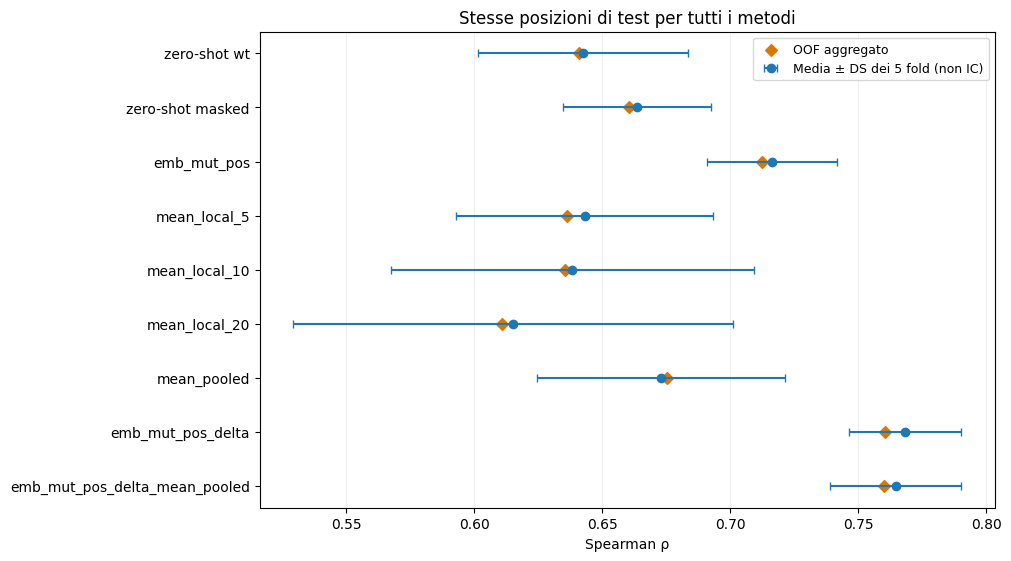

In [4]:
table = result_table({"methods": methods})
spearman_table = table[["n_features", "spearman_fold_mean", "spearman_fold_std", "spearman_oof"]].copy()
spearman_table.columns = ["Feature", "Spearman: media fold", "Spearman: DS fold", "Spearman: OOF aggregato"]
display(spearman_table.round(4))

labels = [name.replace("ridge_", "").replace("zeroshot_", "zero-shot ") for name in table.index]
ypos = np.arange(len(table))
fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
ax.errorbar(table["spearman_fold_mean"], ypos,
            xerr=table["spearman_fold_std"], fmt="o", capsize=3,
            label="Media ± DS dei 5 fold (non IC)")
ax.scatter(table["spearman_oof"], ypos, marker="D", color="#d97706", label="OOF aggregato")
ax.set(yticks=ypos, yticklabels=labels, xlabel="Spearman ρ", title="Stesse posizioni di test per tutti i metodi")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.2)
ax.legend(loc="best", fontsize=9)
plt.show()

,RMSE: media ± DS fold,RMSE: OOF aggregato,MAE: media ± DS fold,MAE: OOF aggregato
method,,,,
ridge_emb_mut_pos,0.8182 ± 0.0132,0.8182,0.6590 ± 0.0124,0.6590
ridge_mean_local_5,0.8935 ± 0.0435,0.8943,0.7262 ± 0.0417,0.7261
ridge_mean_local_10,0.9004 ± 0.0632,0.9020,0.7282 ± 0.0449,0.7280
ridge_mean_local_20,0.9198 ± 0.0754,0.9218,0.7510 ± 0.0551,0.7508
ridge_mean_pooled,0.8759 ± 0.0545,0.8768,0.6990 ± 0.0350,0.6988
ridge_emb_mut_pos_delta,0.7669 ± 0.0181,0.7670,0.6130 ± 0.0205,0.6129
ridge_emb_mut_pos_delta_mean_pooled,0.7681 ± 0.0227,0.7682,0.6094 ± 0.0116,0.6093


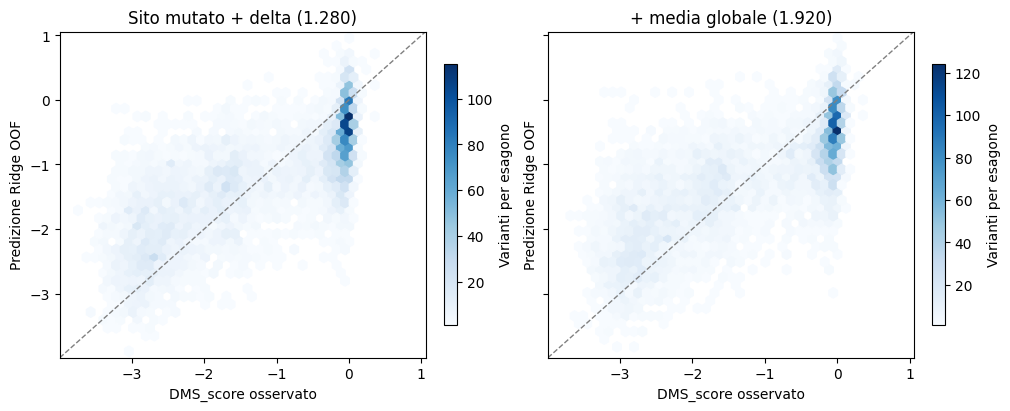

In [5]:
ridge_table = table.loc[table.index.str.startswith("ridge_")]
errors = pd.DataFrame(index=ridge_table.index)
for metric in ["rmse", "mae"]:
    errors[metric.upper() + ": media ± DS fold"] = [
        f"{m:.4f} ± {s:.4f}" for m, s in
        zip(ridge_table[metric + "_fold_mean"], ridge_table[metric + "_fold_std"])]
    errors[metric.upper() + ": OOF aggregato"] = ridge_table[metric + "_oof"].round(4)
display(errors)

# Confronto diretto delle due rappresentazioni annidate.
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained", sharex=True, sharey=True)
plot_methods = [BASE_METHOD, GLOBAL_METHOD]
plot_titles = ["Sito mutato + delta (1.280)", "+ media globale (1.920)"]
values = [predictions["DMS_score"].to_numpy()] + [predictions[m].to_numpy() for m in plot_methods]
lo = min(v.min() for v in values) - 0.1
hi = max(v.max() for v in values) + 0.1
for ax, method, title in zip(axes, plot_methods, plot_titles):
    density = ax.hexbin(predictions["DMS_score"], predictions[method], gridsize=35,
                        mincnt=1, cmap="Blues")
    ax.plot([lo, hi], [lo, hi], "--", color="gray", lw=1)
    ax.set(xlabel="DMS_score osservato", ylabel="Predizione Ridge OOF", title=title,
           xlim=(lo, hi), ylim=(lo, hi))
    fig.colorbar(density, ax=ax, label="Varianti per esagono", shrink=0.8)
plt.show()

## La media globale aggiunge informazione utile?

Confrontiamo le metriche delle due rappresentazioni sugli stessi fold. **Differenza = 1.920 − 1.280**: per Spearman un valore positivo favorisce la nuova rappresentazione; per RMSE/MAE la favorisce un valore negativo. Queste differenze sono descrittive e non costituiscono un test di significatività.

Nel run eseguito, Spearman OOF passa da **0,760519** a **0,760002** (Δ **−0,000517**), RMSE da **0,766976** a **0,768214**, MAE da **0,612920** a **0,609306**. Il nuovo Spearman migliora in 2 fold su 5. L’aggiunta non porta un miglioramento complessivo con questo protocollo; i cambiamenti sono piccoli e misti.

In [6]:
base_report = methods[BASE_METHOD]
global_report = methods[GLOBAL_METHOD]
paired_rows = []
for base, extended in zip(base_report["folds"], global_report["folds"]):
    assert base["fold"] == extended["fold"]
    assert base["inner_splits"] == extended["inner_splits"]
    paired_rows.append({"fold": base["fold"], "Spearman 1280": base["metrics"]["spearman"],
                        "Spearman 1920": extended["metrics"]["spearman"],
                        **{"Δ " + metric: extended["metrics"][metric] - base["metrics"][metric]
                           for metric in ["spearman", "rmse", "mae"]}})
display(pd.DataFrame(paired_rows).set_index("fold").round(4))
print("Differenze sulle predizioni OOF aggregate (1.920 − 1.280):")
for metric in ["spearman", "rmse", "mae"]:
    print(f"  {metric}: {global_report['oof_metrics'][metric] - base_report['oof_metrics'][metric]:+.6f}")

,Spearman 1280,Spearman 1920,Δ spearman,Δ rmse,Δ mae
fold,,,,,
0,0.7721,0.7774,0.0053,-0.0127,-0.0137
1,0.7954,0.7875,-0.0079,0.0076,0.0122
2,0.7796,0.7791,-0.0005,-0.0067,-0.0145
3,0.7390,0.7242,-0.0148,0.0171,0.0054
4,0.7551,0.7554,0.0003,0.0007,-0.0075


Differenze sulle predizioni OOF aggregate (1.920 − 1.280):
  spearman: -0.000517
  rmse: +0.001238
  mae: -0.003614


## Come leggere il confronto

Le predizioni dei regressori riguardano posizioni assenti dal rispettivo training, ma tutti i metodi sono valutati sullo stesso saggio TEM-1. Il confronto delle rappresentazioni rimane esplorativo: scegliere il migliore usando questi risultati non produce un nuovo test indipendente. Le DS fra fold non dimostrano significatività; gli insiemi di training si sovrappongono. Inoltre il WT globale contiene le sequenze di tutti i siti come contesto del pLM: la separazione per posizione riguarda le etichette supervisionate.

Il [CSV OOF](results/supervised_esm2_150m/predictions.csv) e il [JSON](results/supervised_esm2_150m/metrics.json) conservano predizioni per `mutant`, metriche per fold e aggregate, alpha, MSE interni, hash e configurazione. Nessun embedding viene duplicato negli output.

L’estensione conserva i propri [CSV](results/supervised_esm2_150m_global/predictions.csv) e [JSON](results/supervised_esm2_150m_global/metrics.json). Il nuovo run ripete anche il controllo da 1.280 feature e il notebook verifica che le sue predizioni coincidano esattamente con quelle precedenti.